# 00 · La interfaz agente ↔ entorno y el agente aleatorio
**Entornos:** Bandit, MiniDespacho (diminuto), MiniCartas · **Tiempo de ejecución:** ≤ 2 min en CPU ·
**Criterio de la lección:** los tres entornos terminan siempre con opciones legales, el aleatorio en Bandit rinde ≈ 0 y MiniCartas no tiene empates.

## 1. La idea en una frase
Todo el curso usa **una sola interfaz**: el entorno entrega una observación y la **lista de opciones legales**, y el agente
devuelve el **índice** de una de ellas.

**En el sistema de Luca:** el motor del PTCG entrega el estado y las jugadas legales; la red apunta a una de ellas (pointer attention).
**En un problema de negocio:** el despachador entrega los pedidos pendientes y los camiones libres; el agente elige un par (pedido, camión) o espera.

## 2. La intuición y la fórmula
Un episodio es el bucle

$$o_0 \xrightarrow{a_0} (o_1, r_1) \xrightarrow{a_1} (o_2, r_2) \cdots$$

donde $o_t$ incluye las opciones legales $\{1,\dots,n_t\}$ y $a_t \in \{0,\dots,n_t-1\}$ es un **índice**, no un id de acción.
El retorno es $G=\sum_t r_t$. El agente más simple es el **aleatorio**: $a_t \sim \text{Uniforme}\{0,\dots,n_t-1\}$.
Sirve de línea base: cualquier cosa que aprendamos tiene que superarlo con intervalos de confianza, no a ojo.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, seed_everything
from rlf.eval.stats import mean_ci, proportion_ci, passes_lower
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)

from rlf.envs.bandit import Bandit
from rlf.envs.despacho import DespachoEnv
from rlf.envs.cartas import CartasEnv
from rlf.agents.baselines import RandomPolicy
from rlf.eval.arena import evaluate_policy

ENVS = {
    "Bandit": lambda: Bandit(k=10, horizon=300),
    "MiniDespacho (diminuto)": lambda: DespachoEnv.from_size("diminuto"),
    "MiniCartas": lambda: CartasEnv(),
}

## 3. El núcleo: el bucle agente-entorno
Vemos una observación de cada entorno y luego escribimos el bucle a mano. Lo accesorio (entornos, política aleatoria) viene de `rlf/`.

In [2]:
for name, make in ENVS.items():
    env = make()
    obs = env.reset(EVAL_SEED_BASE)
    sp = env.spec
    print(f"{name}: jugadores={sp.n_players}  state={obs.state.shape}  opciones={obs.options.shape}  "
          f"entidades={obs.entities.shape}  max_steps={sp.max_steps}")
    print("   ids de las opciones legales:", obs.option_ids.tolist())

Bandit: jugadores=1  state=(1,)  opciones=(10, 10)  entidades=(0, 1)  max_steps=300
   ids de las opciones legales: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
MiniDespacho (diminuto): jugadores=1  state=(3,)  opciones=(3, 6)  entidades=(3, 6)  max_steps=12
   ids de las opciones legales: [0, 1, 2]
MiniCartas: jugadores=2  state=(12,)  opciones=(1, 19)  entidades=(8, 26)  max_steps=120
   ids de las opciones legales: [13]


In [3]:
def play_one_episode(env, seed, rng):
    """Bucle agente-entorno escrito a mano con un agente aleatorio. Devuelve (retorno jugador 0, nº de pasos, opciones vistas)."""
    obs = env.reset(seed)
    ret, steps, seen, done = 0.0, 0, [], False
    while not done:
        assert obs.n_options >= 1, "siempre debe haber una opción legal"
        seen.append(obs.n_options)
        choice = int(rng.integers(obs.n_options))      # el agente devuelve un ÍNDICE
        st = env.step(choice)
        ret += st.rewards[0]
        obs, done = st.obs, st.done
        steps += 1
    return ret, steps, seen

rng = np.random.default_rng(TRAIN_SEED)
print(play_one_episode(DespachoEnv.from_size("diminuto"), EVAL_SEED_BASE, rng)[:2])

(np.float64(-3.0), 9)


## 4. Correr el aleatorio 1000 veces y graficar
Cada entorno con 1000 episodios de semillas de evaluación (`EVAL_SEED_BASE + i`), nunca de entrenamiento.

Bandit                     pasos/episodio: media  300.0  máx 300 (tope 300)   opciones por decisión: 10.00


MiniDespacho (diminuto)    pasos/episodio: media    8.2  máx  10 (tope 12)   opciones por decisión:  1.76


MiniCartas                 pasos/episodio: media   36.8  máx  53 (tope 120)   opciones por decisión:  3.60


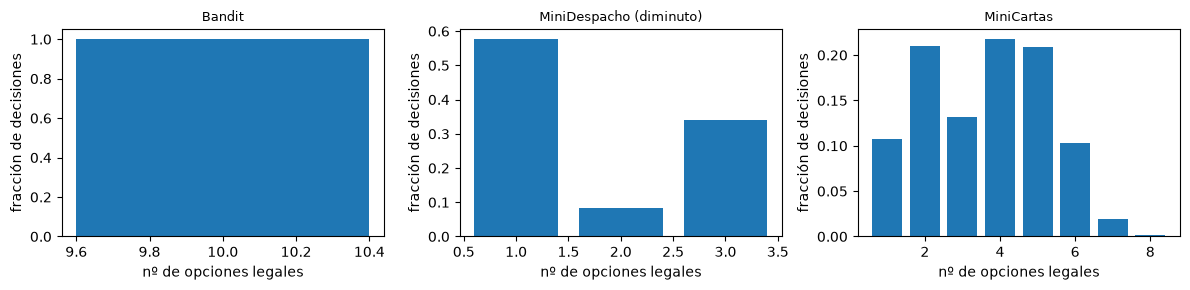

In [4]:
N = 1000
stats = {}
for name, make in ENVS.items():
    env = make()
    rets, steps, opts = [], [], []
    for i in range(N):
        r, s, seen = play_one_episode(env, EVAL_SEED_BASE + i, rng)
        rets.append(r); steps.append(s); opts += seen
    stats[name] = dict(rets=np.array(rets), steps=np.array(steps), opts=np.array(opts), max_steps=env.spec.max_steps)
    print(f"{name:26s} pasos/episodio: media {np.mean(steps):6.1f}  máx {max(steps):3d} (tope {env.spec.max_steps})   "
          f"opciones por decisión: {np.mean(opts):5.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, s) in zip(axes, stats.items()):
    vals, counts = np.unique(s["opts"], return_counts=True)
    ax.bar(vals, counts / counts.sum())
    ax.set_title(name, fontsize=9); ax.set_xlabel("nº de opciones legales"); ax.set_ylabel("fracción de decisiones")
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"
### Experimento 1 · ¿Cuántas opciones legales ve el agente?
**Predice:** en promedio por decisión, ¿cuántas opciones legales hay en Bandit, en MiniDespacho diminuto y en MiniCartas? ¿Cuál varía más?

In [5]:
means = {n: s["opts"].mean() for n, s in stats.items()}
print({n: round(m, 2) for n, m in means.items()})
assert means["Bandit"] == 10.0                                   # siempre los 10 brazos
assert 1.0 < means["MiniDespacho (diminuto)"] < 3.0              # entre esperar y asignar a 2 camiones
assert 2.0 < means["MiniCartas"] < 8.0
assert stats["MiniCartas"]["opts"].std() > 0 and stats["Bandit"]["opts"].std() == 0

{'Bandit': np.float64(10.0), 'MiniDespacho (diminuto)': np.float64(1.76), 'MiniCartas': np.float64(3.6)}


<details><summary>Respuesta esperada</summary>

Bandit: exactamente 10 (todos los brazos son siempre legales, sin variación). MiniDespacho diminuto: ≈ 1,78 (a veces solo
se puede esperar; otras, esperar o asignar a uno de los 2 camiones). MiniCartas: ≈ 3,60, con la mayor variación: depende de la mano,
de si ya se unió energía y de si se puede atacar. Las opciones **variables** son la razón de la interfaz por índices (lección 8).
</details>

### Experimento 2 · ¿Qué pasa si pedimos un índice fuera de rango?
**Predice:** ¿el entorno lo acepta en silencio, o falla? ¿Con qué excepción?

In [6]:
env = DespachoEnv.from_size("diminuto")
obs = env.reset(EVAL_SEED_BASE)
raised = []
for bad in (obs.n_options, -1):
    try:
        env.step(bad)
    except IndexError as e:
        raised.append(type(e).__name__)
print(f"n_options = {obs.n_options}; excepciones: {raised}")
assert raised == ["IndexError", "IndexError"]

n_options = 3; excepciones: ['IndexError', 'IndexError']


<details><summary>Respuesta esperada</summary>

Falla con `IndexError` (tanto con `n_options` como con `-1`): el contrato C5 exige que el índice esté en `[0, n_options)`.
Un entorno que aceptara jugadas ilegales dejaría al agente "hacer trampa" sin que nadie lo note.
</details>

### Experimento 3 · ¿La misma política con otra semilla de entorno da el mismo retorno?
**Predice:** dos corridas con la **misma** semilla, ¿coinciden? ¿Y con semillas distintas en Bandit?

In [7]:
def bandit_return(seed, agent_seed):
    return play_one_episode(Bandit(), seed, np.random.default_rng(agent_seed))[0]

same = [bandit_return(EVAL_SEED_BASE, 7) for _ in range(3)]
diff = [bandit_return(EVAL_SEED_BASE + i, 7) for i in range(5)]
print("misma semilla:", np.round(same, 3), " semillas distintas:", np.round(diff, 3))
assert len(set(same)) == 1 and len(set(np.round(diff, 6))) == 5

misma semilla: [-50.235 -50.235 -50.235]  semillas distintas: [ -50.235  -38.367 -153.148  -32.971  -67.703]


<details><summary>Respuesta esperada</summary>

Con la misma semilla de entorno y del agente el resultado es **idéntico bit a bit** (determinismo, contrato C1). Con semillas de entorno
distintas cambian las medias de los brazos y el ruido, y el retorno cambia. Por eso comparamos agentes sobre las **mismas** semillas (evaluación pareada, lección 2).
</details>

## 6. Criterio de la lección
n = 1000 episodios por entorno con la política aleatoria (semillas `EVAL_SEED_BASE + i`).

In [8]:
# (a) chequeo determinista: todos los episodios terminan, con opciones ≥ 1 (assert dentro del bucle) y en ≤ max_steps
ok_a = all(s["steps"].max() <= s["max_steps"] and len(s["steps"]) == N for s in stats.values())

# (b) chequeo de consistencia: retorno medio por paso del aleatorio en Bandit compatible con 0 (|media| ≤ 3 errores estándar)
per_step = evaluate_policy(lambda: Bandit(), RandomPolicy(TRAIN_SEED), N) / 300
est = mean_ci(per_step)
se = per_step.std(ddof=1) / np.sqrt(N)
ok_b = abs(per_step.mean()) <= 3 * se

# (c) MiniCartas: 1000 partidas aleatorias sin empates (recompensas ±1)
env = CartasEnv(); pol = RandomPolicy(TRAIN_SEED); finals = []
from rlf.core import BatchObs
for i in range(N):
    obs = env.reset(EVAL_SEED_BASE + i); done = False
    while not done:
        st = env.step(int(pol.act(BatchObs.from_obs(obs, env.spec))[0])); obs, done = st.obs, st.done
    finals.append(st.rewards.copy())
finals = np.array(finals)
ok_c = bool(np.isin(finals, [-1.0, 1.0]).all() and (finals.sum(axis=1) == 0).all())

print(f"{'afirmación':60s} resultado")
print(f"{'(a) 3 entornos × 1000 episodios terminan, opciones ≥ 1, pasos ≤ tope':60s} {ok_a}")
print(f"{'(b) Bandit, aleatorio: media por paso = %.4f ± %.4f (|m| ≤ 3 EE)' % (per_step.mean(), se):60s} {ok_b}")
print(f"{'(c) MiniCartas: 1000 partidas con recompensas ±1, sin empates':60s} {ok_c}")
assert ok_a and ok_b and ok_c

afirmación                                                   resultado
(a) 3 entornos × 1000 episodios terminan, opciones ≥ 1, pasos ≤ tope True
(b) Bandit, aleatorio: media por paso = -0.0055 ± 0.0101 (|m| ≤ 3 EE) True
(c) MiniCartas: 1000 partidas con recompensas ±1, sin empates True


## 7. Resumen y puente a la lección siguiente
- Los tres entornos hablan el mismo idioma: `reset → Obs (con opciones legales)`, `step(índice) → (Obs, recompensas, done)`.
- Con el aleatorio ya tenemos una línea base medida con n = 1000: en Bandit ≈ 0, en MiniCartas 50 % por simetría (salvo el sesgo de asiento que veremos en la lección 2).
- **Lección 1:** con esa interfaz, el problema más chico: un Bandit. ¿Cómo explorar sin dejar de explotar?